In [10]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from copy import deepcopy
import pandas as pd

def draw_highlighted_atoms(mol, atom_ids):
    
    local_mol = deepcopy(mol)  # Create a deep copy of the molecule to avoid modifying the original
    for i, atom in enumerate(local_mol.GetAtoms()):
        # For each atom, set the property "molAtomMapNumber" to a custom number, let's say, the index of the atom in the molecule
        atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
    
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(local_mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

In [11]:
smarts_train_fp = "../../data/smarts/fraggnn_d3_mi_ma/smarts_train.csv"
smarts_train_df = pd.read_csv(smarts_train_fp)

smarts_val_fp = "../../data/smarts/fraggnn_d3_mi_ma/smarts_val.csv"
smarts_val_df = pd.read_csv(smarts_val_fp)

smarts_test_fp = "../../data/smarts/fraggnn_d3_mi_ma/smarts_test.csv"
smarts_test_df = pd.read_csv(smarts_test_fp)

In [12]:
import pandas as pd

def get_smarts_df_stats(smarts_dict):
    """
    Generate statistics from a dictionary of {name: DataFrame}, 
    where each DataFrame contains 'prec_type', 'formula', and 'smiles' columns.

    Returns a summary DataFrame with:
    - Total and unique counts of formulas and SMILES per prec_type per dataset
    - Count of overlapping unique formulas and SMILES across prec_types in each dataset
    """
    summary_rows = []

    for name, df in smarts_dict.items():
        grouped = df.groupby('prec_type')
        formula_counts = grouped['formula'].count()
        smiles_counts = grouped['smiles'].count()
        unique_formulas = grouped['formula'].nunique()
        unique_smiles = grouped['smiles'].nunique()

        for prec_type in grouped.groups.keys():
            summary_rows.append({
                'dataset': name,
                'prec_type': prec_type,
                'formula_count': formula_counts[prec_type],
                'smiles_count': smiles_counts[prec_type],
                'unique_formulas': unique_formulas[prec_type],
                'unique_smiles': unique_smiles[prec_type]
            })

        # Overlap calculations using unique formulas/SMILES only
        formula_sets = grouped['formula'].apply(lambda x: set(x.unique()))
        smiles_sets = grouped['smiles'].apply(lambda x: set(x.unique()))

        overlapping_formulas = set.intersection(*formula_sets) if len(formula_sets) > 1 else set()
        overlapping_smiles = set.intersection(*smiles_sets) if len(smiles_sets) > 1 else set()

        summary_rows.append({
            'dataset': name,
            'prec_type': 'OVERLAP',
            'formula_count': len(overlapping_formulas),
            'smiles_count': len(overlapping_smiles),
            'unique_formulas': len(overlapping_formulas),
            'unique_smiles': len(overlapping_smiles)
        })

    return pd.DataFrame(summary_rows)


smarts_dict = {
    'train': smarts_train_df,
    'val': smarts_val_df,
    'test': smarts_test_df
}
get_smarts_df_stats(smarts_dict)

,dataset,prec_type,formula_count,smiles_count,unique_formulas,unique_smiles
0,train,[M+H]+,2636463,2636463,110445,999034
1,train,[M-H]-,1884740,1884740,75017,844768
2,train,OVERLAP,50140,320537,50140,320537
3,val,[M+H]+,910766,910766,60229,387152
4,val,[M-H]-,650964,650964,41284,318935
5,val,OVERLAP,26345,123371,26345,123371
6,test,[M+H]+,894907,894907,55800,385176
7,test,[M-H]-,664593,664593,38208,327666
8,test,OVERLAP,24128,121474,24128,121474


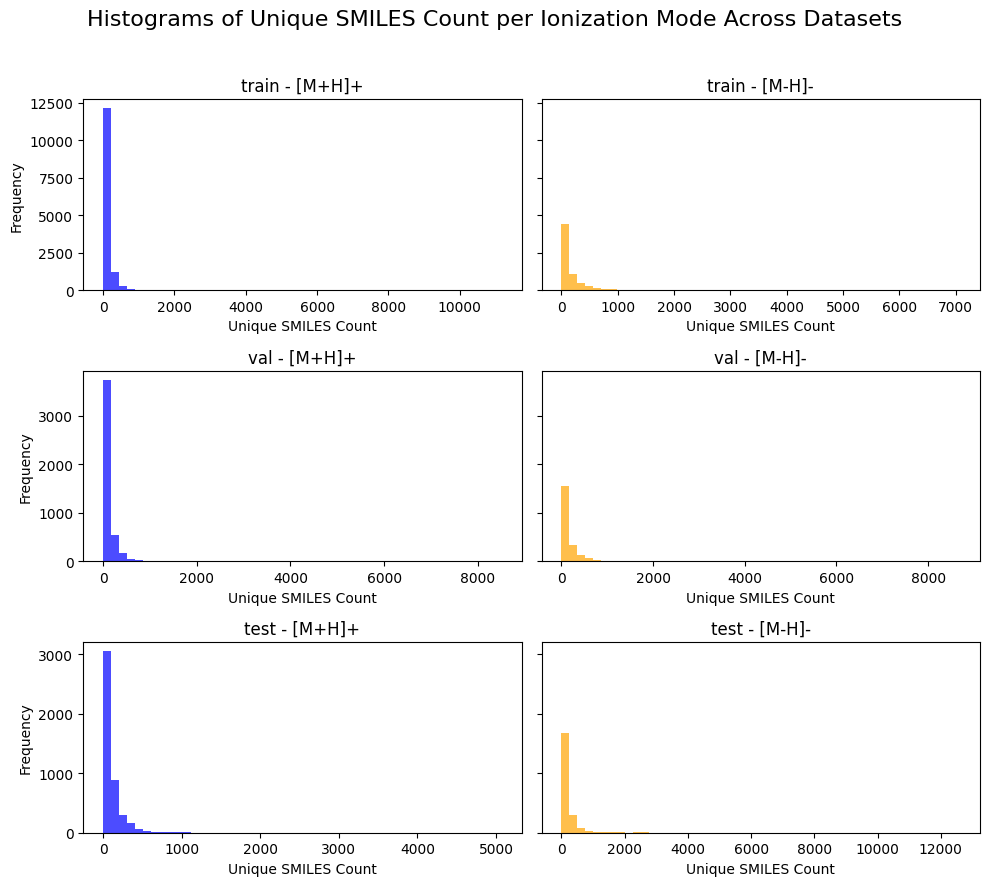

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_unique_smiles_histograms(smarts_dict, smiles_col='smiles', mol_col='mol_smiles', prec_col='prec_type', bins=50):
    """
    Plots histograms of unique SMILES count per mol_smiles for each ionization mode ([M+H]+ and [M-H]-),
    across multiple datasets provided as a dictionary.

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing precursor type, SMILES, and molecule columns.
        smiles_col (str): Column name for SMILES.
        mol_col (str): Column name for molecule identifier (e.g., canonical SMILES).
        prec_col (str): Column name for precursor type (e.g., [M+H]+ or [M-H]-).
        bins (int): Number of histogram bins.
    """
    n = len(smarts_dict)
    fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(10, 3 * n), sharey='row')

    if n == 1:
        axes = [axes]  # ensure iterable even when 1 dataset

    for idx, (name, df) in enumerate(smarts_dict.items()):
        # Count unique SMILES per mol_smiles within each prec_type
        unique_counts = (
            df.groupby([prec_col, mol_col])[smiles_col]
            .nunique()
            .reset_index()
            .rename(columns={smiles_col: 'unique_smiles_count'})
        )

        mh_plus_data = unique_counts[unique_counts[prec_col] == '[M+H]+']
        mh_minus_data = unique_counts[unique_counts[prec_col] == '[M-H]-']

        ax1, ax2 = axes[idx]

        # [M+H]+ Histogram
        ax1.hist(mh_plus_data['unique_smiles_count'], bins=bins, color='blue', alpha=0.7)
        ax1.set_title(f'{name} - [M+H]+')
        ax1.set_xlabel('Unique SMILES Count')
        ax1.set_ylabel('Frequency')

        # [M-H]- Histogram
        ax2.hist(mh_minus_data['unique_smiles_count'], bins=bins, color='orange', alpha=0.7)
        ax2.set_title(f'{name} - [M-H]-')
        ax2.set_xlabel('Unique SMILES Count')

    plt.suptitle('Histograms of Unique SMILES Count per Ionization Mode Across Datasets', fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

plot_unique_smiles_histograms(smarts_dict)

In [ ]:
import pandas as pd
from itertools import combinations

def get_unique_smiles_overlap_by_precursor(smarts_dict, smiles_col='smiles', prec_col='prec_type'):
    """
    Computes pairwise SMILES overlaps across datasets, grouped by precursor type (e.g., [M+H]+, [M-H]-).

    Parameters:
        smarts_dict (dict): Dictionary of {name: DataFrame}, each containing a SMILES and prec_type column.
        smiles_col (str): Column name for SMILES (default: 'smiles').
        prec_col (str): Column name for precursor type (default: 'prec_type').

    Returns:
        overlap_df (pd.DataFrame): DataFrame with per-precursor-type pairwise SMILES overlap stats:
            - dataset_1, dataset_2
            - overlap_count
            - overlap_%_of_dataset_1
            - overlap_%_of_dataset_2
            - prec_type
        global_overlap_dict (dict): {prec_type: set of SMILES shared across all datasets for that type}
    """
    all_prec_types = set().union(*[set(df[prec_col].dropna().unique()) for df in smarts_dict.values()])
    overlap_rows = []
    global_overlap_dict = {}

    for prec in all_prec_types:
        # Extract SMILES sets for this precursor from each dataset
        smiles_sets = {
            name: set(df[df[prec_col] == prec][smiles_col].unique())
            for name, df in smarts_dict.items()
        }

        # Remove empty sets (datasets without this precursor)
        smiles_sets = {k: v for k, v in smiles_sets.items() if v}

        # Skip if fewer than 2 datasets contain this precursor
        if len(smiles_sets) < 2:
            continue

        # Pairwise comparisons
        for (name1, set1), (name2, set2) in combinations(smiles_sets.items(), 2):
            intersect = set1 & set2
            overlap_count = len(intersect)
            percent_in_1 = 100 * overlap_count / len(set1) if set1 else 0
            percent_in_2 = 100 * overlap_count / len(set2) if set2 else 0

            overlap_rows.append({
                'prec_type': prec,
                'dataset_1': name1,
                'dataset_2': name2,
                'overlap_count': overlap_count,
                'overlap_%_of_dataset_1': round(percent_in_1, 2),
                'overlap_%_of_dataset_2': round(percent_in_2, 2),
            })

        # Global intersection for this precursor
        global_overlap_dict[prec] = set.intersection(*smiles_sets.values())

    overlap_df = pd.DataFrame(overlap_rows)
    return overlap_df, global_overlap_dict

overlap_df, global_smiles = get_unique_smiles_overlap_by_precursor(smarts_dict)
overlap_df


,prec_type,dataset_1,dataset_2,overlap_count,overlap_%_of_dataset_1,overlap_%_of_dataset_2
0,[M-H]-,train,val,64938,7.69,20.36
1,[M-H]-,train,test,64121,7.59,19.57
2,[M-H]-,val,test,35410,11.10,10.81
3,[M+H]+,train,val,93016,9.31,24.03
4,[M+H]+,train,test,95335,9.54,24.75
5,[M+H]+,val,test,55191,14.26,14.33
